In [14]:
import os
from dotenv import load_dotenv

load_dotenv()

True

In [15]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, TensorDataset
from torchvision import datasets, transforms
import os
import random
import numpy as np

SEED = 0
torch.manual_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
g = torch.Generator()
g.manual_seed(0)



device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'  # or ':16:8'


################################
#     RESTART     RUNTIME      #
################################
from ssonn.model.utils import *
from ssonn.metrics.nonlinearity_metrics import *
from ssonn.metrics.edge_finder import *
from ssonn.metrics.train_metrics import *
from ssonn.train.train import *

In [16]:
class SimpleFCN(nn.Module):
    def __init__(self, input_size=28 * 28, hidden_size=16):
        super(SimpleFCN, self).__init__()
        self.fc0 = nn.Linear(input_size, 10)
        # self.fc1 = nn.Linear(hidden_size, 10)
        # self.act = nn.ReLU()

    def forward(self, x):
        x = self.fc0(x)
        return x

In [17]:
hyperparams = {
    "num_epochs": 32,
    "batch_size": 256,
    "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()), # replace to default
    "edge_score_aggregation": "mean",
    "expansion_thresholds": {"fc0": 0.4},
    "pruning_thresholds": {"fc0": 1},
    "plateau_threshold": 0.05,
    "min_epochs_between_expansions": 8,
    # "min_epochs_between_expansions": 10_000,
    "plateau_window_size": 5,
    "learning_rate": 1e-3,
    "prune_after_epochs": 4,
    "task_type": "classification",
    "start_fully_connected": False,
    "max_new_edges_per_expansion": 2000,
    "weight_decay": 1e-4,
    "diff_threshold": 0.05
}

In [18]:
# Dataset and Dataloader
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1))
])

# Load dataset and split into train/validation sets
dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

train_dataset, val_dataset = random_split(dataset, [0.8, 0.2])

train_loader = DataLoader(train_dataset, batch_size=hyperparams['batch_size'], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=hyperparams['batch_size'], shuffle=False)

In [19]:
# Test loader (MNIST test split)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=hyperparams['batch_size'], shuffle=False)


In [20]:
model = SimpleFCN()
sparse_model = convert_dense_to_sparse_network(model, layers=[model.fc0], device=device)

In [21]:
# import wandb
# wandb.login()

In [22]:
# wandb.finish()
# run = wandb.init(
#     project="self-expanding-nets",
#     name=f"name",
#     config=hyperparams
# )

In [23]:
from comet_ml import start
from comet_ml.integration.pytorch import log_model

print("COMET_API_KEY present?", bool(os.getenv("COMET_API_KEY")))
print("COMET_WORKSPACE:", os.getenv("COMET_WORKSPACE"))

experiment = start(
    api_key=os.environ.get("COMET_API_KEY"),
    workspace=os.environ.get("COMET_WORKSPACE"),
    project_name="mnist_desktop_imaging_2SGD",
)
experiment.log_parameters(hyperparams)
experiment.set_name("trash")

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.


COMET_API_KEY present? True
COMET_WORKSPACE: gcof


COMET INFO: Experiment is live on comet.com https://www.comet.com/gcof/mnist-desktop-imaging-2sgd/c1b63aeee5304531accb0439aaf113e1



In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    sparse_model.parameters(),
    lr=hyperparams["learning_rate"],
    momentum=0.9,
    weight_decay=hyperparams["weight_decay"],
    nesterov=True,   # можно False, если хочешь проще
)


state = train_sparse_recursive(
    model=sparse_model,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer,
    hyperparams=hyperparams,
    device=device,
    experiment=experiment,
)


100%|██████████| 188/188 [00:04<00:00, 43.05it/s]


Epoch 1/32, Train Loss: 1.6963, Val Loss: 1.2254, Val Accuracy: 0.7949


100%|██████████| 188/188 [00:04<00:00, 40.87it/s]
COMET INFO: Trying to log a figure that is exceeding allowed SVG file size limit (1072060 > 1048576). Falling back to PNG format.


Epoch 2/32, Train Loss: 1.0529, Val Loss: 0.8860, Val Accuracy: 0.8341


100%|██████████| 188/188 [00:04<00:00, 39.25it/s]
COMET INFO: Trying to log a figure that is exceeding allowed SVG file size limit (1109457 > 1048576). Falling back to PNG format.


Epoch 3/32, Train Loss: 0.8303, Val Loss: 0.7375, Val Accuracy: 0.8526


... (54 outputs left out)

100%|██████████| 188/188 [00:27<00:00,  6.73it/s]
COMET INFO: Trying to log a figure that is exceeding allowed SVG file size limit (3839102 > 1048576). Falling back to PNG format.


Epoch 31/32, Train Loss: 0.3778, Val Loss: 0.3492, Val Accuracy: 0.9054


100%|██████████| 188/188 [00:27<00:00,  6.81it/s]
COMET INFO: Trying to log a figure that is exceeding allowed SVG file size limit (3813986 > 1048576). Falling back to PNG format.


Epoch 32/32, Train Loss: 0.3659, Val Loss: 0.3395, Val Accuracy: 0.9074


In [25]:
experiment.end()

COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : trash
COMET INFO:     url                   : https://www.comet.com/gcof/mnist-desktop-imaging-2sgd/c1b63aeee5304531accb0439aaf113e1
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     acc amount [32]               : (1.6667008726250958e-06, 0.0001139030612244898)
COMET INFO:     lr [32]                       : (0.00025, 0.001)
COMET INFO:     n_params over train_time [32] : (1631.1577065952788, 142297.83450506616)
COMET INFO:     params amount [32]            : (7840, 535969)
COMET INFO:     params ratio [32]             : (0.7771683673469387, 0.9962684408986341)
COMET INFO:     params to replace amount [32] : (282, 2000)
COMET INFO:     train

In [12]:
torch.save(sparse_model, 'mnist.pt')

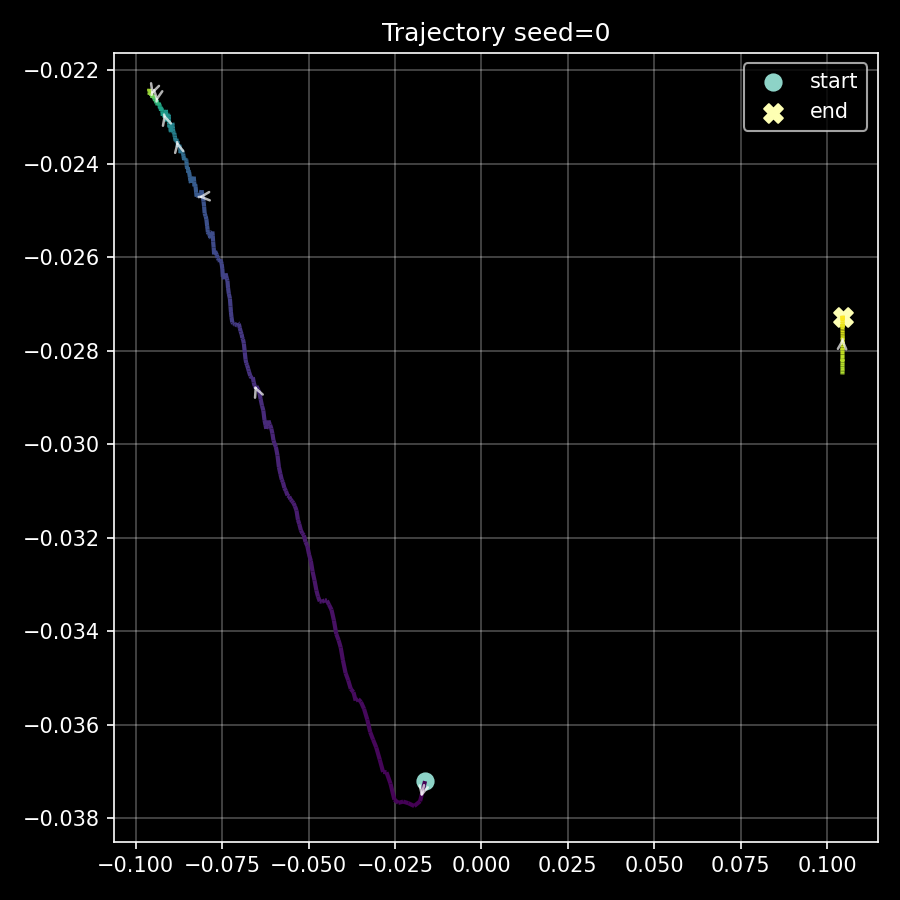

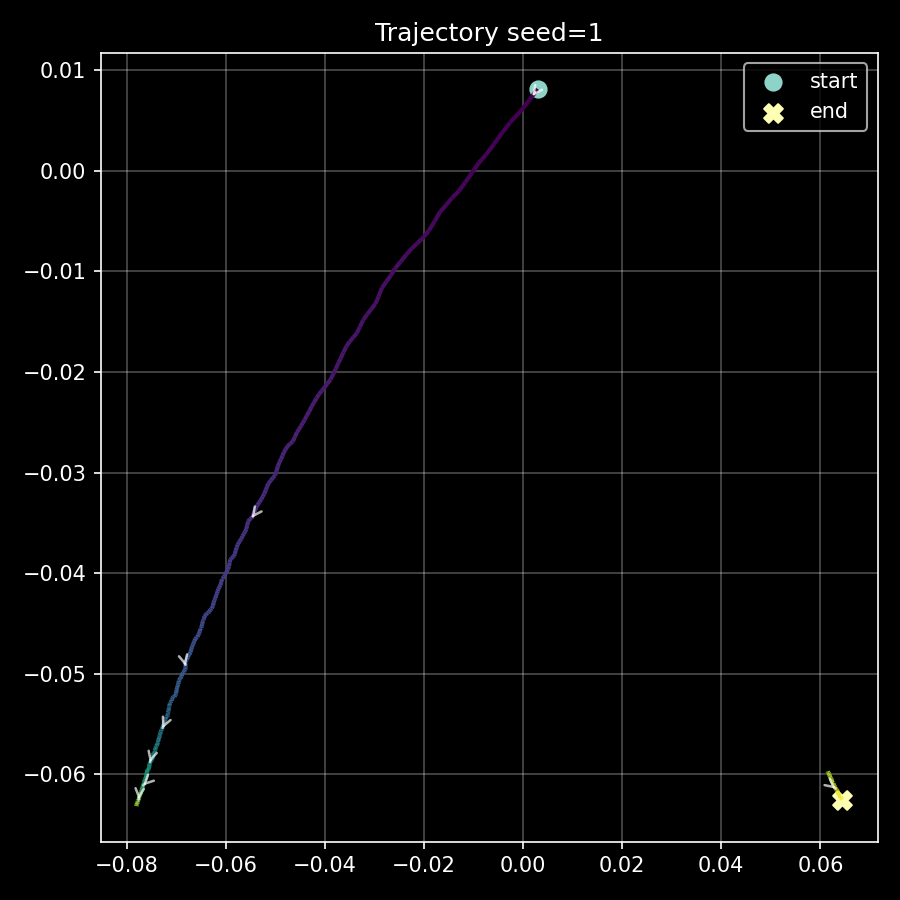

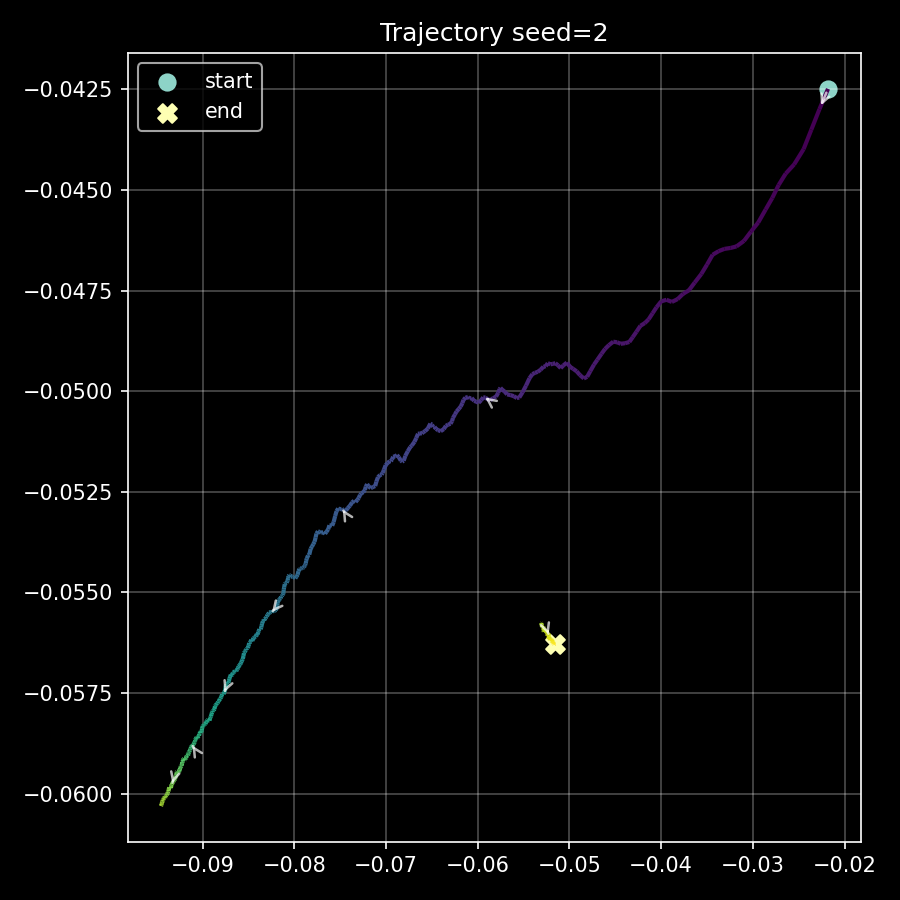

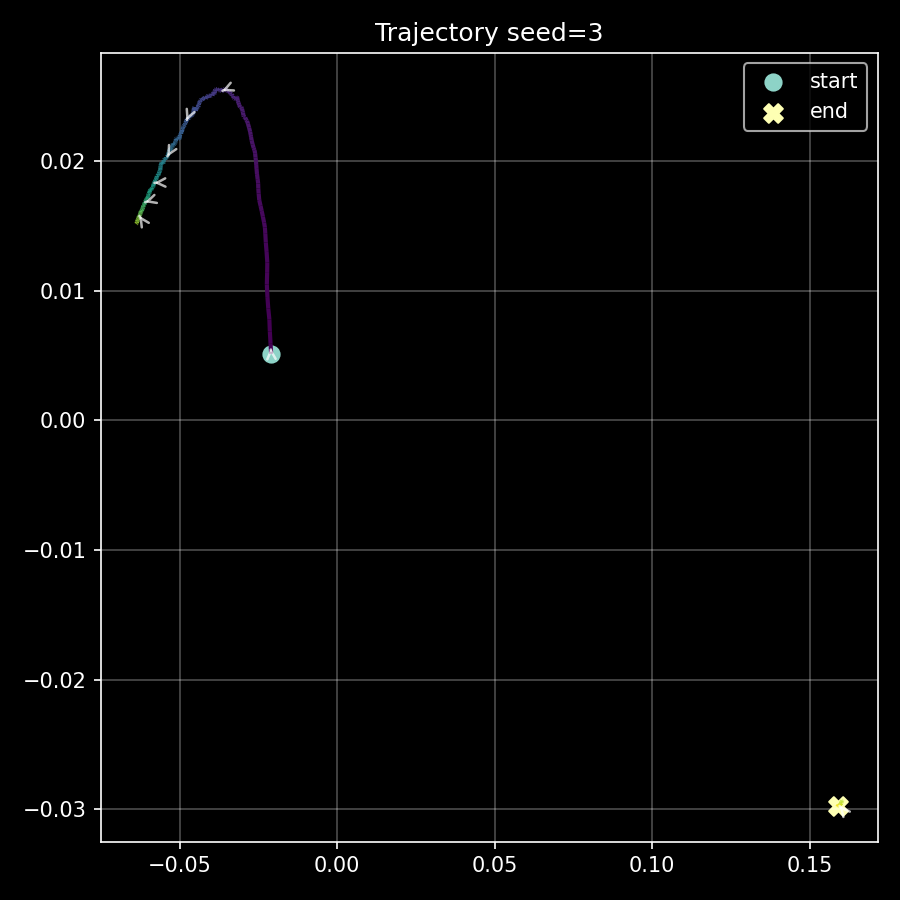

In [26]:
from IPython.display import Image, display
import os

out_dir = "traj_plots"  # тот же, что ты используешь в train.py
for seed in [0, 1, 2, 3]:
    p = os.path.join(out_dir, f"trajectory_seed{seed}.png")
    if os.path.exists(p):
        display(Image(filename=p))
